In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, Matern, WhiteKernel
from scipy.stats import norm
from scipy.optimize import minimize
from scipy.stats import qmc
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

# Import our visualization functions
from plotting_utils import (
    plot_gp_1d, plot_acquisition_1d, plot_bo_iteration_1d,
    plot_2d_function, plot_2d_bo_state, plot_convergence,
    plot_parallel_coordinates
)
from pathlib import Path
import sys


# Set random seed for reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-darkgrid')

In [2]:


# ---------------------------------------------------------
# 1. Load the .npy data for each function into a dictionary
# ---------------------------------------------------------
base_path = Path(r'C:\Users\OWNER\Downloads\Initial_data_points_starter\initial_data')

data = {}
for i in range(1, 9):
    folder = base_path / f'function_{i}'
    data[i] = {
        'inputs': np.load(folder / 'initial_inputs.npy'),
        'outputs': np.load(folder / 'initial_outputs.npy'),
    }

# ---------------------------------------------------------
# 2. Hardcoded descriptive metadata for each function
# ---------------------------------------------------------
function_info = {
    1: {
        'input_dim': '2D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.',
        'description': (
            "Detect likely contamination sources in a two-dimensional area, such as a radiation "
            "field, where only proximity yields a non-zero reading. The system uses Bayesian "
            "optimisation to tune detection parameters and reliably identify both strong and weak sources."
        ),
    },
    2: {
        'input_dim': '2D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Maximise a noisy 2-input log-likelihood score from a black-box ML model, avoiding local optima.',
        'description': (
            "Imagine a black box, or a mystery ML model, that takes two numbers as input and returns "
            "a log-likelihood score. Your goal is to maximise that score, but each output is noisy, "
            "and depending on where you start, you might get stuck in a local optimum.\n\n"
            "To tackle this, you use Bayesian optimisation, which selects the next inputs based on "
            "what it has learned so far. It balances exploration with exploitation, making it well "
            "suited to noisy outputs and complex functions with many local peaks."
        ),
    },
    3: {
        'input_dim': '3D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Minimise drug side effects (framed as maximisation) across 3 compound-dose inputs.',
        'description': (
            "You're working on a drug discovery project, testing combinations of three compounds to "
            "create a new medicine.\n\n"
            "Each experiment is stored in initial_inputs.npy as a 3D array, where each row lists the "
            "amounts of the three compounds used. After each experiment, you record the number of "
            "adverse reactions, stored in initial_outputs.npy as a 1D array.\n\n"
            "Your goal is to minimise side effects; in this competition, it is framed as maximisation "
            "by optimising a transformed output (e.g. the negative of side effects)."
        ),
    },
    4: {
        'input_dim': '4D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Tune 4 hyperparameters of a warehouse-placement approximation model against an expensive baseline.',
        'description': (
            "Address the challenge of optimally placing products across warehouses for a business "
            "with high online sales, where accurate calculations are costly and only feasible "
            "biweekly. To speed up decision-making, an ML model approximates these results within "
            "hours. The model has four hyperparameters to tune, and its output reflects the "
            "difference from the expensive baseline. Because the system is dynamic and full of "
            "local optima, it requires careful tuning and robust validation to find reliable, "
            "near-optimal solutions."
        ),
    },
    5: {
        'input_dim': '4D array',
        'output_dim': '1D array',
        'goal': 'Maximise',
        'summary': 'Maximise yield of a unimodal 4-input chemical process.',
        'description': (
            "You're tasked with optimising a four-variable black-box function that represents the "
            "yield of a chemical process in a factory. The function is typically unimodal, with a "
            "single peak where yield is maximised.\n\n"
            "Your goal is to find the optimal combination of chemical inputs that delivers the "
            "highest possible yield, using systematic exploration and optimisation methods."
        ),
    },
    6: {
        'input_dim': '5D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Optimise a 5-ingredient cake recipe, maximising a negative expert-judged score toward zero.',
        'description': (
            "You're optimising a cake recipe using a black-box function with five ingredient inputs, "
            "for example flour, sugar, eggs, butter and milk. Each recipe is evaluated with a "
            "combined score based on flavour, consistency, calories, waste and cost, where each "
            "factor contributes negative points as judged by an expert taster. This means the total "
            "score is negative by design.\n\n"
            "To frame this as a maximisation problem, your goal is to bring that score as close to "
            "zero as possible or, equivalently, to maximise the negative of the total sum."
        ),
    },
    7: {
        'input_dim': '6D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Maximise ML model performance by tuning 6 hyperparameters.',
        'description': (
            "You're tasked with optimising an ML model by tuning six hyperparameters, for example "
            "learning rate, regularisation strength or number of hidden layers. The function you're "
            "maximising is the model's performance score (such as accuracy or F1), but since the "
            "relationship between inputs and output isn't known, it's treated as a black-box function.\n\n"
            "Because this is a commonly used model, you might benefit from researching best practices "
            "or literature to guide your initial search space. Your goal is to find the combination "
            "of hyperparameters that yields the highest possible performance."
        ),
    },
    8: {
        'input_dim': '8D',
        'output_dim': '1D',
        'goal': 'Maximise',
        'summary': 'Maximise an 8-hyperparameter validation accuracy score; strong local maxima are a practical target.',
        'description': (
            "You're optimising an eight-dimensional black-box function, where each of the eight "
            "input parameters affects the output, but the internal mechanics are unknown.\n\n"
            "Your objective is to find the parameter combination that maximises the function's "
            "output, such as performance, efficiency or validation accuracy. Because the function is "
            "high-dimensional and likely complex, global optimisation is hard, so identifying strong "
            "local maxima is often a practical strategy.\n\n"
            "For example, imagine you're tuning an ML model with eight hyperparameters: learning "
            "rate, batch size, number of layers, dropout rate, regularisation strength, activation "
            "function (numerically encoded), optimiser type (encoded) and initial weight range. Each "
            "input set returns a single validation accuracy score between 0 and 1. Your goal is to "
            "maximise this score."
        ),
    },
}

# ---------------------------------------------------------
# 3. Add the real element count, read straight from the data
#    (rather than hardcoded, so it's always accurate)
# ---------------------------------------------------------
for i in range(1, 9):
    function_info[i]['original_element_count'] = data[i]['outputs'].shape[0]
    function_info[i]['element_count'] = function_info[i]['original_element_count'] 

# ---------------------------------------------------------
# 4. Merge info into the data dict for single-point access
# ---------------------------------------------------------
for i in range(1, 9):
    data[i]['info'] = function_info[i]
print (data[1])


{'inputs': array([[0.31940389, 0.76295937],
       [0.57432921, 0.8798981 ],
       [0.73102363, 0.73299988],
       [0.84035342, 0.26473161],
       [0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.68341817, 0.86105746],
       [0.08250725, 0.40348751],
       [0.88388983, 0.58225397]]), 'outputs': array([ 1.32267704e-079,  1.03307824e-046,  7.71087511e-016,
        3.34177101e-124, -3.60606264e-003, -2.15924904e-054,
       -2.08909327e-091,  2.53500115e-040,  3.60677119e-081,
        6.22985647e-048]), 'info': {'input_dim': '2D array', 'output_dim': '1D array', 'goal': 'Maximise', 'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.', 'description': 'Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and 

In [3]:
# load additional readings 
inputs_week12 = [
    [0.529898, 0.147279],
    [0.708951, 0.],
    [1., 1., 0.828175],
    [0.425474, 0.395517, 0.36094, 0.411679],
    [0.257143, 0.49982, 1., 0.99297],
    [0.289894, 0., 0.147955, 1., 0.],
    [0., 0.338137, 0.355396, 0.132998, 0.372845, 0.773692],
    [0.141895, 0.095432, 0.159456, 0., 1., 0.379385, 0.137654, 0.33106],
]
outputs_week12 = np.array(
[4.053428008350997e-63,
 0.5552587474771571,
 -0.07941258446450565,
 0.6125296791453043,
 1711.945439547402,
 -1.353607855778981,
 1.677647239313782,
 9.918854085501]    
)
for i, row in enumerate(inputs_week12):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['element_count'] = data[i+1]['info']['original_element_count'] + 1
for i, col in enumerate(outputs_week12):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])



{'inputs': array([[0.31940389, 0.76295937],
       [0.57432921, 0.8798981 ],
       [0.73102363, 0.73299988],
       [0.84035342, 0.26473161],
       [0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.68341817, 0.86105746],
       [0.08250725, 0.40348751],
       [0.88388983, 0.58225397],
       [0.529898  , 0.147279  ]]), 'outputs': array([ 1.32267704e-079,  1.03307824e-046,  7.71087511e-016,
        3.34177101e-124, -3.60606264e-003, -2.15924904e-054,
       -2.08909327e-091,  2.53500115e-040,  3.60677119e-081,
        6.22985647e-048,  4.05342801e-063]), 'info': {'input_dim': '2D array', 'output_dim': '1D array', 'goal': 'Maximise', 'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.', 'description': 'Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detectio

In [4]:
# load additional readings 
inputs_week13 = [
[0.02725 , 0.086909],
[0.961968, 0.      ],
[0., 0., 0.],
[0.434583, 0.429955, 0.200617, 0.449818],
[1., 0., 1., 1.],
[0.141044, 1.      , 0.      , 1.      , 0.049934],
[0.      , 0.164509, 0.031516, 0.      , 0.355541, 1.      ],
[0.122837, 0.132208, 0.111196, 0.282165, 1.      , 0.557382,
       0.250889, 0.974698]

]
outputs_week13 = np.array(
[-1.1964394027512214e-186,
 0.024151137433858324,
 -0.17239781799687137,
 -3.1185913551321742,
 4440.5225,
 -1.7437453725953456,
 0.3634687180335354,
 9.9376000954386]
)
for i, row in enumerate(inputs_week13):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['element_count'] = data[i+1]['info']['element_count'] + 1
for i, col in enumerate(outputs_week13):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])



{'inputs': array([[0.31940389, 0.76295937],
       [0.57432921, 0.8798981 ],
       [0.73102363, 0.73299988],
       [0.84035342, 0.26473161],
       [0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.68341817, 0.86105746],
       [0.08250725, 0.40348751],
       [0.88388983, 0.58225397],
       [0.529898  , 0.147279  ],
       [0.02725   , 0.086909  ]]), 'outputs': array([ 1.32267704e-079,  1.03307824e-046,  7.71087511e-016,
        3.34177101e-124, -3.60606264e-003, -2.15924904e-054,
       -2.08909327e-091,  2.53500115e-040,  3.60677119e-081,
        6.22985647e-048,  4.05342801e-063, -1.19643940e-186]), 'info': {'input_dim': '2D array', 'output_dim': '1D array', 'goal': 'Maximise', 'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.', 'description': 'Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The

In [5]:
# load additional readings 
inputs_week14 = [

[0.839255, 0.104077],
[0.689358, 1.      ],
[0.55, 0.65, 0.15],
[0.3806, 0.4001, 0.4317, 0.4443],
[0.95, 0.02, 1.  , 1.  ],
[0.735, 0.14 , 0.745, 0.7  , 0.05 ],
[0.  , 0.4 , 0.3 , 0.2 , 0.39, 0.76],
[0.13 , 0.11 , 0.135, 0.15 , 1.   , 0.465, 0.19 , 0.5  ]
]
outputs_week14 = np.array(
[-2.748441588472043e-192,
 0.6445010131383366,
 -0.09261282572565534,
 0.10596447065193049,
 3819.753553371859,
 -0.7481068297892876,
 1.6532943330108063,
 9.9741]
)
for i, row in enumerate(inputs_week14):
    data[i+1]['inputs'] = np.vstack([data[i+1]['inputs'], row] )
    data[i+1]['info']['element_count'] = data[i+1]['info']['element_count'] + 1
for i, col in enumerate(outputs_week14):
    data[i+1]['outputs'] = np.append(data[i+1]['outputs'], col )

print (data[1])


{'inputs': array([[0.31940389, 0.76295937],
       [0.57432921, 0.8798981 ],
       [0.73102363, 0.73299988],
       [0.84035342, 0.26473161],
       [0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.68341817, 0.86105746],
       [0.08250725, 0.40348751],
       [0.88388983, 0.58225397],
       [0.529898  , 0.147279  ],
       [0.02725   , 0.086909  ],
       [0.839255  , 0.104077  ]]), 'outputs': array([ 1.32267704e-079,  1.03307824e-046,  7.71087511e-016,
        3.34177101e-124, -3.60606264e-003, -2.15924904e-054,
       -2.08909327e-091,  2.53500115e-040,  3.60677119e-081,
        6.22985647e-048,  4.05342801e-063, -1.19643940e-186,
       -2.74844159e-192]), 'info': {'input_dim': '2D array', 'output_dim': '1D array', 'goal': 'Maximise', 'summary': 'Locate contamination sources in a 2D field using sparse, proximity-based readings.', 'description': 'Detect likely contamination sources in a two-dimensional area, such as a radiation 

In [6]:
# ---------------------------------------------------------
# Print the functions
# ---------------------------------------------------------
for challenge_function_idx in range(1, 9):
    print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} "
          f"(n={data[challenge_function_idx]['info']['element_count']})")
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0])    
    min_function_params = np.full(reading_dim_cnt, np.inf)
    min_function_output  = np.inf
    max_function_params = np.full(reading_dim_cnt, -np.inf)
    max_function_output  = -np.inf
    for reading_idx in range (0, data[challenge_function_idx]['info']['element_count']):
        target_function = 'f'+ str(challenge_function_idx) + "("
        # number of elements in each reading
        reading_dim_cnt = len(data[challenge_function_idx]["inputs"][reading_idx])
        
        for reading_dim_idx in range(reading_dim_cnt):
            reading_dim_val = data[challenge_function_idx]["inputs"][reading_idx][reading_dim_idx]
            target_function = target_function + str(reading_dim_val) 
            if reading_dim_val < min_function_params[reading_dim_idx] :
                min_function_params[reading_dim_idx] = reading_dim_val 
            if reading_dim_val > max_function_params[reading_dim_idx] :
                max_function_params[reading_dim_idx] = reading_dim_val 
            if reading_dim_idx == reading_dim_cnt - 1:
                function_output = data[challenge_function_idx]["outputs"][reading_idx]
                if function_output == max(data[challenge_function_idx]["outputs"]) :
                    maxout = " MAX"
                else:
                    maxout = ""      
                target_function = target_function + ") = " + str(function_output) + maxout 
            else:
                target_function = target_function + ","
        print (target_function )
        if function_output < min_function_output :
            min_function_output = function_output 
        if function_output > max_function_output :
            max_function_output = function_output 
                    
    print ("min_function_params ", min_function_params, 
           "min_function_output ", min_function_output )     
    print ("max_function_params ", max_function_params, 
           "max_function_output ", max_function_output )     
           


Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings. (n=13)
f1(0.31940388883889725,0.7629593742689353) = 1.3226770395454077e-79
f1(0.5743292145098291,0.879898104984359) = 1.0330782375230975e-46
f1(0.7310236309563586,0.7329998764152272) = 7.710875114502849e-16 MAX
f1(0.8403534169072556,0.26473161399676703) = 3.341771007676023e-124
f1(0.6501140597987644,0.6815263520602101) = -0.0036060626443634764
f1(0.41043713662518566,0.14755429902998185) = -2.1592490357331095e-54
f1(0.31269115679477755,0.07872277794971883) = -2.0890932702320842e-91
f1(0.6834181688515067,0.8610574643936101) = 2.5350011535584046e-40
f1(0.08250725182080587,0.403487506426324) = 3.6067711901420254e-81
f1(0.8838898288181171,0.5822539743824439) = 6.229856468168659e-48
f1(0.529898,0.147279) = 4.053428008350997e-63
f1(0.02725,0.086909) = -1.1964394027512214e-186
f1(0.839255,0.104077) = -2.748441588472043e-192
min_function_params  [0.02725    0.07872278] min_function_output  -0.0036060

In [7]:
# ---------------------------------------------------------
# Vectorise the functions and results 
# ---------------------------------------------------------
for challenge_function_idx in range(1, 9):
    reading_cnt = data[challenge_function_idx]['info']['element_count']
    data[challenge_function_idx]["Y"] = np.zeros(shape=(reading_cnt))
    print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} "
          f"(n={reading_cnt})")
    # number of readings taken 
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0])    
    data[challenge_function_idx]["X"] = np.zeros(shape=(reading_cnt,reading_dim_cnt))
    for reading_idx in range (0, reading_cnt):
        reading_dim_cnt = len(data[challenge_function_idx]["inputs"][reading_idx])
        
        for reading_dim_idx in range(reading_dim_cnt):
            reading_dim_val = data[challenge_function_idx]["inputs"][reading_idx][reading_dim_idx]
            data[challenge_function_idx]["X"][reading_idx][reading_dim_idx] = reading_dim_val
        function_output = data[challenge_function_idx]["outputs"][reading_idx]
        data[challenge_function_idx]["Y"][reading_idx] = function_output
    print ( "X_samples = np.array(",data[challenge_function_idx]["X"], ")" )
    print ( "y_samples = np.array(",data[challenge_function_idx]["Y"], ")" )
           


Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings. (n=13)
X_samples = np.array( [[0.31940389 0.76295937]
 [0.57432921 0.8798981 ]
 [0.73102363 0.73299988]
 [0.84035342 0.26473161]
 [0.65011406 0.68152635]
 [0.41043714 0.1475543 ]
 [0.31269116 0.07872278]
 [0.68341817 0.86105746]
 [0.08250725 0.40348751]
 [0.88388983 0.58225397]
 [0.529898   0.147279  ]
 [0.02725    0.086909  ]
 [0.839255   0.104077  ]] )
y_samples = np.array( [ 1.32267704e-079  1.03307824e-046  7.71087511e-016  3.34177101e-124
 -3.60606264e-003 -2.15924904e-054 -2.08909327e-091  2.53500115e-040
  3.60677119e-081  6.22985647e-048  4.05342801e-063 -1.19643940e-186
 -2.74844159e-192] )

Function 2: Maximise a noisy 2-input log-likelihood score from a black-box ML model, avoiding local optima. (n=13)
X_samples = np.array( [[0.66579958 0.12396913]
 [0.87779099 0.7786275 ]
 [0.14269907 0.34900513]
 [0.84527543 0.71112027]
 [0.45464714 0.29045518]
 [0.57771284 0.77197318]
 [0.43816

In [8]:
# output to .csvs 
for challenge_function_idx in range(1, 9):
    # Ensure 2D shapes for column stacking
    y = data[challenge_function_idx]['outputs'].reshape(-1, 1) if data[challenge_function_idx]['outputs'].ndim == 1 else data[challenge_function_idx]['outputs']
    X = data[challenge_function_idx]['inputs']
    if X.ndim == 1:
        X = X.reshape(-1, 1)
    
    # Combine y and X horizontally
    combined_data = np.hstack([y, X])
    
    # Generate headers: y, x1, x2, ..., xN
    num_inputs = X.shape[1]
    headers = ['y'] + [f'x{i+1}' for i in range(num_inputs)]
    
    # Export to CSV
    df = pd.DataFrame(combined_data, columns=headers)
    filename = f'challenge{challenge_function_idx}.csv'
    df.to_csv(filename, index=False)
    print(f"Exported {filename} with columns: {headers}")

Exported challenge1.csv with columns: ['y', 'x1', 'x2']
Exported challenge2.csv with columns: ['y', 'x1', 'x2']
Exported challenge3.csv with columns: ['y', 'x1', 'x2', 'x3']
Exported challenge4.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4']
Exported challenge5.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4']
Exported challenge6.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4', 'x5']
Exported challenge7.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6']
Exported challenge8.csv with columns: ['y', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']


In [9]:
# initialise variables
next_submission = np.zeros(shape=(9,8))
submission_results = {
    i: {"prediction": 0.0, "sigma_percentage": 0.0}
    for i in range(9)
}
length_scales = np.zeros(shape=(9,8))


In [10]:
def upper_confidence_bound(mu, sigma, kappa=2.0):
    return mu + kappa * sigma

def expected_improvement(mu, sigma, y_best, xi=0.01):
    """
    Expected Improvement (EI) acquisition function.
    
    EI = E[max(f(x) - f(x_best), 0)]
    
    Parameters:
    -----------
    mu : predicted mean
    sigma : predicted standard deviation  
    y_best : best observed value so far
    xi : exploration parameter
    """
    with np.errstate(divide='warn'):
        improvement = mu - y_best - xi
        Z = improvement / sigma
        ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
        ei[sigma == 0.0] = 0.0
    return ei

def neg_acquisition_ucb(x, gp, kappa):
    x = x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD
    mu, sigma = gp.predict(x, return_std=True)
    return -upper_confidence_bound(mu, sigma, kappa)

def neg_acquisition_ei(x, gp, y_best, xi=0.01):
    x = x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD
    mu, sigma = gp.predict(x, return_std=True)
#    return -expected_improvement(mu[0], sigma[0], y_best, xi)
    return -expected_improvement(mu, sigma, y_best, xi)

def propose_next_point(gp, acq_method, y_best, dim=2, n_restarts=20, xi=0.01, kappa=2):
    # Well-spread starting points via Sobol sequence -- scales far better
    # than uniform random for covering a d-dimensional cube evenly
    sampler = qmc.Sobol(d=dim, scramble=True)
    starts = sampler.random_base2(m=int(np.ceil(np.log2(n_restarts))))  # power-of-2 count

    best_x, best_val = None, np.inf
    for x0 in starts:
        if acq_method == "UCB" :
            res = minimize(
                neg_acquisition_ucb, x0,
                args=(gp, kappa),
                bounds=[(0, 1)] * dim,
                method='L-BFGS-B'
            )
        else :
            res = minimize(
                neg_acquisition_ei, x0,
                args=(gp, y_best, xi),
                bounds=[(0, 1)] * dim,
                method='L-BFGS-B'
            )
        if res.fun < best_val:
            best_val = res.fun
            best_x = res.x

    return best_x, -best_val



In [11]:
# Function 3-8: 

acq_method = "EI"
ucb_kappa = 2.0
ei_xi = 0.01

challenge_function_idx = 8
X_samples = data[challenge_function_idx]["X"]
y_samples = data[challenge_function_idx]["Y"]
#X_samples = data[challenge_function_idx]["X"][:data[challenge_function_idx]['info']['original_element_count']]
#y_samples = data[challenge_function_idx]["Y"][:data[challenge_function_idx]['info']['original_element_count']]
reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0]) 
print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} ",
          f"(n={data[challenge_function_idx]['info']['element_count']})")
print ( data[challenge_function_idx]['info']['description'])
#print ( f"{X_samples=}" ) 
#print ( f"{y_samples=}" ) 


kernel = ConstantKernel(1.0) * RBF(length_scale=[0.2] * reading_dim_cnt)
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,
                                     n_restarts_optimizer=100)
gp.fit(X_samples, y_samples)

print("Fitted kernel:", gp.kernel_)
print(f" {gp.log_marginal_likelihood(gp.kernel_.theta)=} ")
length_scales[challenge_function_idx][:reading_dim_cnt] = gp.kernel_.k2.length_scale 
y_best = y_samples.max()
print (f' {y_best=} ' )


next_x, next_y = propose_next_point(gp, acq_method, y_best, dim=reading_dim_cnt, n_restarts=20, xi=ei_xi, kappa=ucb_kappa )
print (f'{acq_method} Optimiser {next_x=}  {next_y=} ' )
if acq_method == "UCB" :
    next_x4p = next_x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD

    next_mu, next_sigma = gp.predict(next_x4p, return_std=True)
    mu_contribution = next_mu 
    sigma_contribution = ucb_kappa * next_sigma
    est_next_y = mu_contribution + sigma_contribution
    sigma_pct = float(sigma_contribution / est_next_y * 100.00)
    print (f'{mu_contribution=} {sigma_contribution=} {est_next_y=} {sigma_pct=}')
else :
    sigma_pct = 0 
    
for reading_dim_idx in range (0, reading_dim_cnt):
    next_submission[challenge_function_idx][reading_dim_idx] = next_x[reading_dim_idx] 
submission_results[challenge_function_idx] = {"prediction": next_y, "sigma_percentage": sigma_pct}
# override if neccessary
# week 14 
#next_submission[3][:3] = 0.55, 0.65, 0.15 # excel inspection.
#next_submission[4][:4] = 0.3806, 0.4001, 0.4317, 0.4443 # sharp peak observation
#next_submission[5][:4] = 0.950000, 0.020000, 1.000000, 1.000000
#next_submission[6][:5] = 0.735000, 0.140000, 0.745000, 0.700000, 0.050000
#next_submission[7][:6] = 0.000000, 0.400000, 0.300000, 0.200000, 0.390000, 0.760000
#next_submission[8][:8] = 0.1300, 0.1100, 0.1350, 0.1500, 1.0000, 0.4650, 0.1900, 0.5000
#print (f"{next_submission=}")



Function 8: Maximise an 8-hyperparameter validation accuracy score; strong local maxima are a practical target.  (n=43)
You're optimising an eight-dimensional black-box function, where each of the eight input parameters affects the output, but the internal mechanics are unknown.

Your objective is to find the parameter combination that maximises the function's output, such as performance, efficiency or validation accuracy. Because the function is high-dimensional and likely complex, global optimisation is hard, so identifying strong local maxima is often a practical strategy.

For example, imagine you're tuning an ML model with eight hyperparameters: learning rate, batch size, number of layers, dropout rate, regularisation strength, activation function (numerically encoded), optimiser type (encoded) and initial weight range. Each input set returns a single validation accuracy score between 0 and 1. Your goal is to maximise this score.
Fitted kernel: 1.99**2 * RBF(length_scale=[1.7, 2.


Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings.  (no=10) (n=13)
Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and weak sources.
X_samples=array([[0.31940389, 0.76295937],
       [0.57432921, 0.8798981 ],
       [0.73102363, 0.73299988],
       [0.84035342, 0.26473161],
       [0.65011406, 0.68152635],
       [0.41043714, 0.1475543 ],
       [0.31269116, 0.07872278],
       [0.68341817, 0.86105746],
       [0.08250725, 0.40348751],
       [0.88388983, 0.58225397],
       [0.529898  , 0.147279  ],
       [0.02725   , 0.086909  ],
       [0.839255  , 0.104077  ]])
y_samples=array([ 1.32267704e-079,  1.03307824e-046,  7.71087511e-016,
        3.34177101e-124, -3.60606264e-003, -2.15924904e-054,
       -2.08909327e-091,  2.53500115e-040,  3.60677119e-081

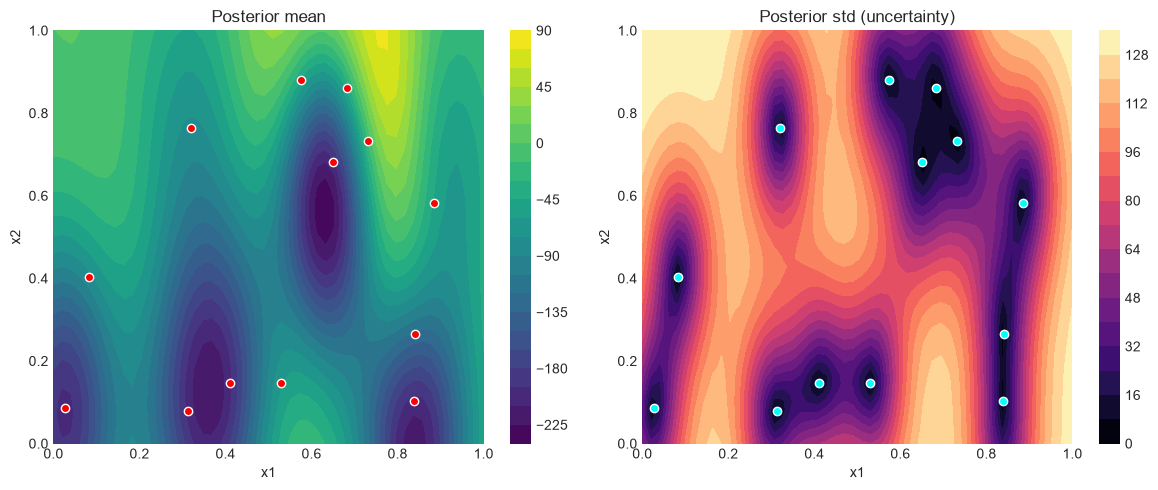

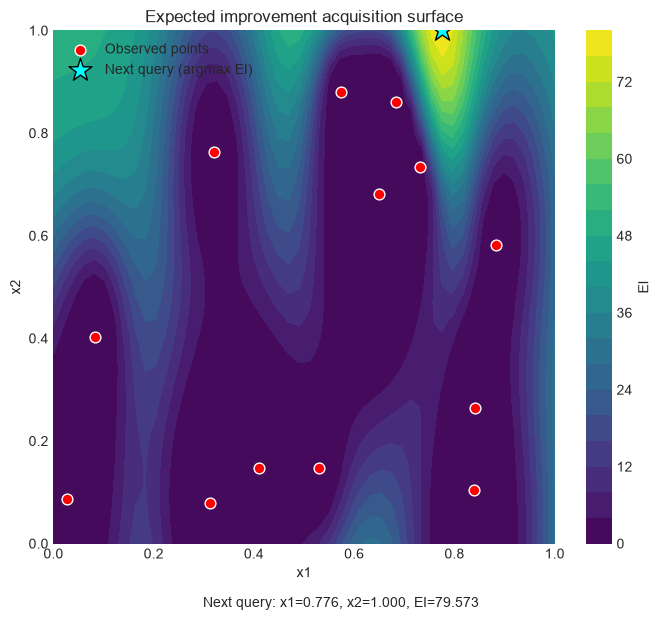

EI Grid Search best_x1=np.float64(0.7755102040816326)  best_x2=np.float64(1.0)  79.57282244226118 
EI Optimiser next_x=array([0.4821702, 1.       ])  next_y=66.03490342268594 


In [12]:
# Function 2: Maximise a noisy 2-input log-likelihood score from a black-box ML model, avoiding local optima. (n=10)
# Function 1: Locate contamination sources in a 2D field using sparse, proximity-based readings. (n=10)

acq_method = "EI"
ucb_kappa = 2.0
ei_xi = 0.01

challenge_function_idx = 1
X_samples = data[challenge_function_idx]["X"]
y_samples = data[challenge_function_idx]["Y"]
reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0]) 
print(f"\nFunction {challenge_function_idx}: {data[challenge_function_idx]['info']['summary']} ",
          f"(no={data[challenge_function_idx]['info']['original_element_count']})",
          f"(n={data[challenge_function_idx]['info']['element_count']})"
          )
print ( data[challenge_function_idx]['info']['description'])
print ( f"{X_samples=}" ) 
print ( f"{y_samples=}" ) 
NOISE_FLOOR = 1e-200
if challenge_function_idx == 1 :
    y_samples = np.log10( np.clip(y_samples,a_min=NOISE_FLOOR, a_max=None) )
    print ( f"log10 {y_samples=}" ) 
#========================================================================================
# Gaussian function calc 
#========================================================================================
if challenge_function_idx == 1 or challenge_function_idx == 2 :
    kernel = ConstantKernel(1.0) * RBF(length_scale=[0.2,0.2])
else : # function 2 is noisy but this didnt improve things
    kernel = ConstantKernel(1.0, (1e-3, 1e3)) \
         * RBF(length_scale=[0.3, 0.3], length_scale_bounds=(1e-2, 1e2)) \
         + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e0))
gp = GaussianProcessRegressor(kernel=kernel, alpha=1e-6,
                                     n_restarts_optimizer=100)

gp.fit(X_samples, y_samples)

print("Fitted kernel:", gp.kernel_)
print(gp.log_marginal_likelihood(gp.kernel_.theta))
length_scales[challenge_function_idx][:reading_dim_cnt] = gp.kernel_.k2.length_scale 

x1_grid = np.linspace(0, 1, 50)
x2_grid = np.linspace(0, 1, 50)
X1, X2 = np.meshgrid(x1_grid, x2_grid)

# Flatten into (2500, 2) — the shape gp.predict expects
grid_points = np.column_stack([X1.ravel(), X2.ravel()])
mean, std = gp.predict(grid_points, return_std=True)

# Reshape predictions back into the 2D grid shape for plotting
mean_grid = mean.reshape(X1.shape)
std_grid = std.reshape(X1.shape)

#========================================================================================
# Gaussian function graphs of mean and std 
#========================================================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

c1 = axes[0].contourf(X1, X2, mean_grid, levels=20, cmap='viridis')
axes[0].scatter(X_samples[:, 0], X_samples[:, 1], color='red', edgecolor='white', zorder=5)
axes[0].set_title('Posterior mean')
axes[0].set_xlabel('x1'); axes[0].set_ylabel('x2')
plt.colorbar(c1, ax=axes[0])

c2 = axes[1].contourf(X1, X2, std_grid, levels=20, cmap='magma')
axes[1].scatter(X_samples[:, 0], X_samples[:, 1], color='cyan', edgecolor='white', zorder=5)
axes[1].set_title('Posterior std (uncertainty)')
axes[1].set_xlabel('x1'); axes[1].set_ylabel('x2')
plt.colorbar(c2, ax=axes[1])

plt.tight_layout()


#========================================================================================
#  Acquisition functions UCB/EI
#========================================================================================



# Evaluate UCB/EI across the flattened grid (grid_points, mu, sigma from earlier meshgrid code)
if acq_method == "UCB":
   acq_val = upper_confidence_bound(mean_grid, std_grid, kappa=ucb_kappa)
else:
   acq_val = expected_improvement(mean_grid, std_grid, y_best, xi=ei_xi)


best_row, best_col = np.unravel_index(np.argmax(acq_val), acq_val.shape)
best_x1 = X1[best_row, best_col]
best_x2 = X2[best_row, best_col]
best_val = acq_val[best_row, best_col]

print(f"Next query: x1={best_x1:.4f}, x2={best_x2:.4f}, {acq_method}={best_val:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))

c = ax.contourf(X1, X2, acq_val, levels=20, cmap='viridis')
plt.colorbar(c, ax=ax, label=acq_method)

# Existing observations
ax.scatter(X_samples[:, 0], X_samples[:, 1], color='red', edgecolor='white',
           s=60, zorder=5, label='Observed points')

# The proposed next query — where UCB is maximized
ax.scatter(best_x1, best_x2, color='cyan', edgecolor='black', marker='*',
           s=300, zorder=6, label=f'Next query (argmax {acq_method})')
y_best = y_samples.max()



ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.legend(loc='upper left')
if acq_method == "UCB" : 
   ax.set_title('Upper Confidence Bound acquisition surface')
   # Caption with the actual values, right under the plot
   fig.text(0.5, -0.02,
          f"Next query: x1={best_x1:.3f}, x2={best_x2:.3f}, UCB={best_val:.3f}  (κ={2.0})",
          ha='center', fontsize=10)
else:
   ax.set_title('Expected improvement acquisition surface')
   # Caption with the actual values, right under the plot
   fig.text(0.5, -0.02,
          f"Next query: x1={best_x1:.3f}, x2={best_x2:.3f}, EI={best_val:.3f}  ",
          ha='center', fontsize=10)

plt.tight_layout()
plt.show()


print (f'{acq_method} Grid Search {best_x1=}  {best_x2=}  {best_val} ' )

y_best = y_samples.max()
next_x, next_y = propose_next_point(gp, acq_method, y_best, dim=2, n_restarts=20, xi=ei_xi, kappa=ucb_kappa )
print (f'{acq_method} Optimiser {next_x=}  {next_y=} ' )

if acq_method == "UCB" :
    next_x4p = next_x.reshape(1, -1)          # scipy passes a flat array; gp.predict wants nD

    next_mu, next_sigma = gp.predict(next_x4p, return_std=True)
    mu_contribution = next_mu 
    sigma_contribution = ucb_kappa * next_sigma
    est_next_y = mu_contribution + sigma_contribution
    sigma_pct = float(sigma_contribution / est_next_y * 100.00)
    print (f'{mu_contribution=} {sigma_contribution=} {est_next_y=} {sigma_pct=}')
else :
    sigma_pct = 0 
    
for reading_dim_idx in range (0, reading_dim_cnt):
    next_submission[challenge_function_idx][reading_dim_idx] = next_x[reading_dim_idx] 
submission_results[challenge_function_idx] = {"prediction": next_y, "sigma_percentage": sigma_pct}

# override if neccessary
# week 15 
next_submission[1][:2] = 0.7310236,0.7429998 # close probe east f1(0.7310236309563586,0.7329998764152272)
#next_submission[2][:2] = 0.3806, 0.4001, 0.4317, 0.4443 # sharp peak observation


In [19]:
for challenge_function_idx in range(1, 9):
    # number of reading elements each time a reading is taken
    reading_dim_cnt = len(data[challenge_function_idx]["inputs"][0])    
    portal_output = ""
    for reading_dim_idx in range (0, reading_dim_cnt):
        if reading_dim_idx == reading_dim_cnt - 1:     
            portal_output = portal_output + f"{next_submission[challenge_function_idx][reading_dim_idx]:.6f}" 
        else:
            portal_output = portal_output + f"{next_submission[challenge_function_idx][reading_dim_idx]:.6f}" + "-"   
    print (challenge_function_idx, portal_output, 
                '*  prediction',submission_results[challenge_function_idx]["prediction"],
                ' ',submission_results[challenge_function_idx]["sigma_percentage"],'%'
                                      )
for challenge_function_idx in range(1, 9):
    print(f"{challenge_function_idx} {submission_results[challenge_function_idx]['sigma_percentage']:.0f}%")

print("\nLength Scales ")
for challenge_function_idx in range(1, 9):
    print(f"{challenge_function_idx} {length_scales[challenge_function_idx]}")


1 0.731024-0.743000 *  prediction 99.65023263969243   0 %
2 0.000000-0.829310 *  prediction 0.0011192964212374127   0 %
3 0.789640-1.000000-0.439476 *  prediction 0.0590654583828053   0 %
4 0.000000-0.000000-1.000000-1.000000 *  prediction 0.3915211643400578   0 %
5 1.000000-0.561350-0.428393-0.987530 *  prediction 3.5464321893399218   0 %
6 0.578043-0.299842-1.000000-1.000000-0.000000 *  prediction 0.8300811301174181   0 %
7 0.000000-0.425438-0.333622-0.248521-0.405577-0.806397 *  prediction 0.05767813536370661   0 %
8 0.228797-0.351247-0.037923-0.320776-0.054109-0.088993-0.154376-0.881937 *  prediction 4.444057602256157e-13   0 %
1 0%
2 0%
3 0%
4 0%
5 0%
6 0%
7 0%
8 0%

Length Scales 
1 [0.09068304 0.29103537 0.         0.         0.         0.
 0.         0.        ]
2 [0.05818139 2.69960573 0.         0.         0.         0.
 0.         0.        ]
3 [1.00000000e+05 1.03332594e+00 9.04316049e-02 0.00000000e+00
 0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00]
4 [0.5795